<a href="https://colab.research.google.com/github/Amyerm/ClassFiles/blob/main/Validaci%C3%B3n%2C_Evaluaci%C3%B3n_y_Selecci%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Validación, Evaluación y Selección
**Objetivo**
Aplicar de forma integral el proceso de entrenamiento, ajuste y evaluación de un clasificador tipo Árbol de Decisión sobre un conjunto de datos grande, aplicando técnicas robustas de validación cruzada y optimización de hiperparámetros.

Dataset: Glioma Grading Clinical and Mutation Features.
---


---
## 1. Carga de Bibliotecas, Conjunto de Datos y Análisis Exploratorio de los Datos

In [1]:
!pip install ucimlrepo -q

In [2]:
# Importar bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    RandomizedSearchCV,
    GridSearchCV
)

In [3]:
# Cargar el conjunto de datos

glioma = fetch_ucirepo(id=759)

X = glioma.data.features
y = glioma.data.targets["Grade"]

df = pd.concat([X, y], axis=1)

df.head()

,Gender,Age_at_diagnosis,Race,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,...,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA,Grade
0,0,51.30,white,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,38.72,white,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,0,35.17,white,1,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,32.78,white,1,1,1,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
4,0,31.51,white,1,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
# Dimensiones del dataset

print("Dimensiones:", df.shape)
print("Variables predictoras:", X.shape[1])
print("Variable objetivo:", y.name)

Dimensiones: (839, 24)
Variables predictoras: 23
Variable objetivo: Grade


---
## 2. 📊 Análisis exploratorio de datos (EDA)

In [5]:
# Estructura del dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Gender            839 non-null    int64  
 1   Age_at_diagnosis  839 non-null    float64
 2   Race              839 non-null    object 
 3   IDH1              839 non-null    int64  
 4   TP53              839 non-null    int64  
 5   ATRX              839 non-null    int64  
 6   PTEN              839 non-null    int64  
 7   EGFR              839 non-null    int64  
 8   CIC               839 non-null    int64  
 9   MUC16             839 non-null    int64  
 10  PIK3CA            839 non-null    int64  
 11  NF1               839 non-null    int64  
 12  PIK3R1            839 non-null    int64  
 13  FUBP1             839 non-null    int64  
 14  RB1               839 non-null    int64  
 15  NOTCH1            839 non-null    int64  
 16  BCOR              839 non-null    int64  
 1

In [6]:
# Estadísticas descriptivas

df.describe()

,Gender,Age_at_diagnosis,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,...,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA,Grade
count,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,...,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000
mean,0.418355,50.935411,0.481526,0.414779,0.258641,0.168057,0.133492,0.132300,0.116806,0.087008,...,0.047676,0.045292,0.034565,0.032181,0.032181,0.032181,0.027414,0.027414,0.026222,0.419547
std,0.493583,15.702339,0.499957,0.492978,0.438149,0.374140,0.340309,0.339019,0.321380,0.282015,...,0.213206,0.208068,0.182784,0.176586,0.176586,0.176586,0.163383,0.163383,0.159889,0.493779
min,0.000000,14.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,38.055000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,51.550000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,62.800000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,1.000000,89.290000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
# Distribución de las clases

y.value_counts()

,count
Grade,
0,487
1,352


**2.1 Histogramas**

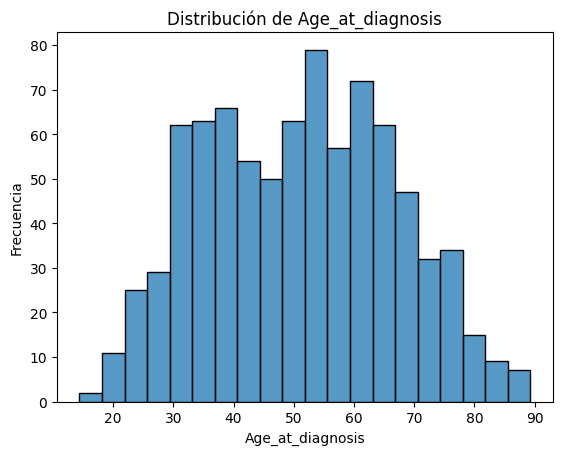

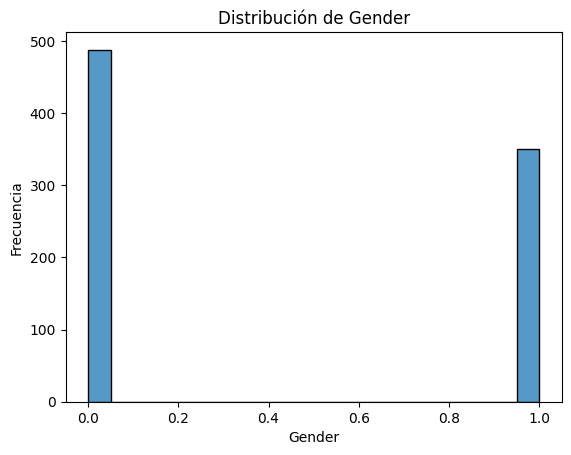

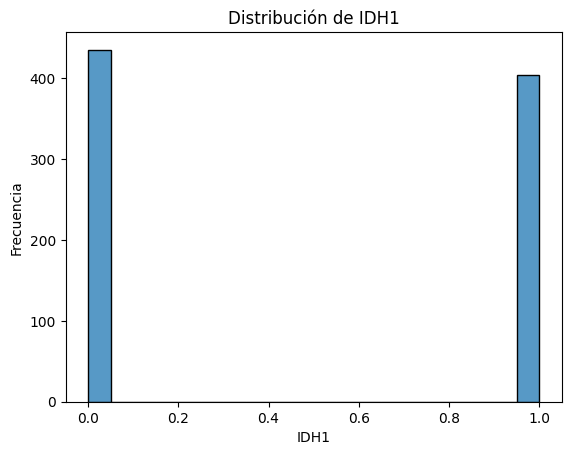

In [8]:
# Histogramas de variables numéricas

variables = ["Age_at_diagnosis", "Gender", "IDH1"]

for variable in variables:
    sns.histplot(df[variable], bins=20)
    plt.title("Distribución de " + variable)
    plt.xlabel(variable)
    plt.ylabel("Frecuencia")
    plt.show()

**Interpretación de los histogramas**

En Age_at_diagnosis se observa que la mayoría de las edades se concentra aproximadamente entre los 30 y 70 años, con una mayor frecuencia alrededor de los 50 y 60 años.

En Gender se observa que hay más registros con valor 0 que con valor 1, aunque la diferencia no es demasiado grande.

Por último, IDH1 presenta una distribución relativamente equilibrada entre sus valores 0 y 1, con una cantidad ligeramente mayor de registros con valor 0.

**2.2 Boxplots por clase**

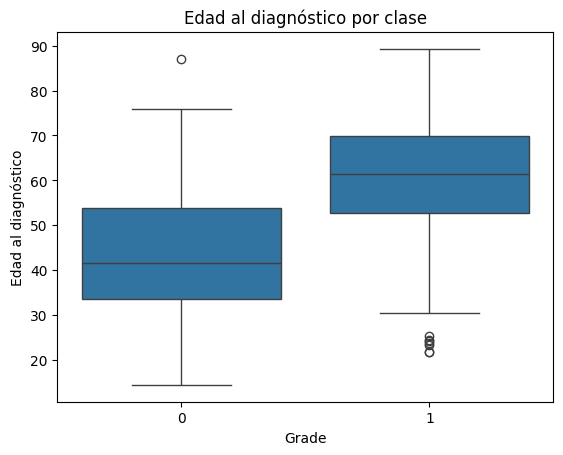

In [9]:
# Boxplot de edad por clase

sns.boxplot(
    data=df,
    x="Grade",
    y="Age_at_diagnosis"
)

plt.title("Edad al diagnóstico por clase")
plt.xlabel("Grade")
plt.ylabel("Edad al diagnóstico")
plt.show()

**Interpretación del boxplot**

Se observa que las edades al diagnóstico son diferentes entre las dos clases. En Grade 0, la mediana se encuentra aproximadamente en 42 años, mientras que en Grade 1 está cerca de los 62 años. Los pacientes de la clase 1 tienden a presentar edades mayores al momento del diagnóstico. También se observan algunos valores atípicos en ambas clases.

**2.3 Mapa de calor de correlaciones**

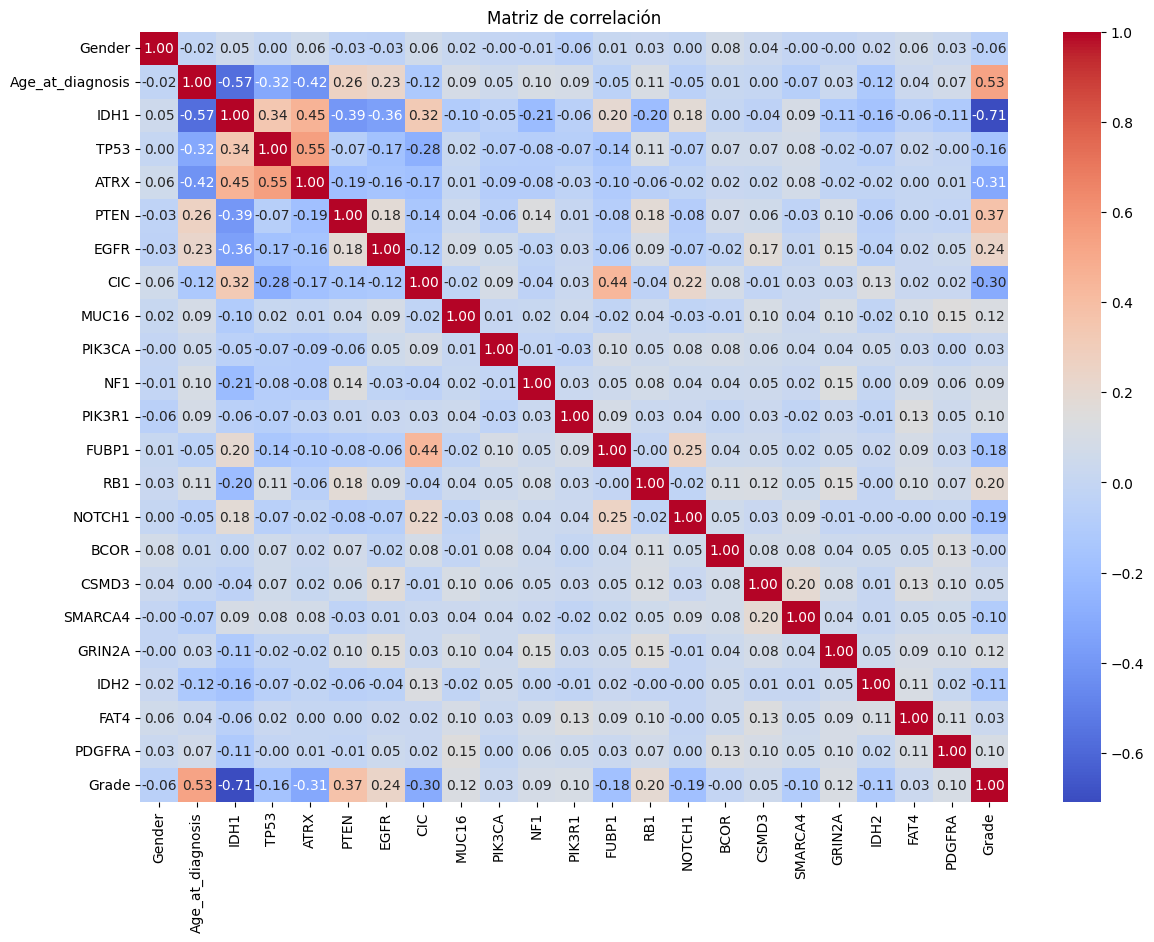

In [10]:
# Matriz de correlación

correlacion = df.select_dtypes(include="number").corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlacion,
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Matriz de correlación")
plt.show()

**Interpretación de la matriz de correlación**

En la matriz se observa que IDH1 presenta la correlación más fuerte con Grade, con un valor aproximado de -0.71, lo que indica una relación negativa. Age_at_diagnosis también muestra una correlación importante, cercana a 0.53, pero positiva. Otras variables como PTEN, TP53 y EGFR presentan relaciones menores. Esto sugiere que IDH1 y la edad al diagnóstico podrían ser atributos útiles para diferenciar las clases.

**¿Existen clases desbalanceadas?**

Sí, existe un desbalance moderado. La clase 0 contiene 487 registros y la clase 1 tiene 352, lo que representa aproximadamente un 58% y un 42%, respectivamente. Aunque la diferencia no es demasiado grande, utilizar StratifiedKFold ayudará a conservar estas proporciones durante la validación cruzada.

**¿Qué atributos parecen más informativos?**

Los atributos que parecen más informativos son IDH1 y Age_at_diagnosis, ya que presentan las correlaciones más fuertes con Grade. En el boxplot se observa una diferencia importante en las edades entre ambas clases. También podrían aportar información variables como PTEN y TP53, aunque sus correlaciones son menores.

---
## 3. Gráfica de Errores en Entrenamiento y Prueba

**3.1 Preparar las variables**

In [11]:
# Preparar los datos para el modelo

X_modelo = pd.get_dummies(X, columns=["Race"], dtype=int)

X_modelo.head()

,Gender,Age_at_diagnosis,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,...,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA,Race_american indian or alaska native,Race_asian,Race_black or african american,Race_white
0,0,51.30,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
1,0,38.72,1,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
2,0,35.17,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,1,32.78,1,1,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
4,0,31.51,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


**3.2 Configurar StratifiedKFold**

In [12]:
# Validación cruzada estratificada

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=3
)

**3.3 Entrenar árboles con diferentes profundidades**

In [13]:
# Comparación de profundidades

profundidades = [2, 5, 10, 15, 20, 25, 30, None]

f1_train = []
f1_test = []

for profundidad in profundidades:
    arbol = DecisionTreeClassifier(
        max_depth=profundidad,
        random_state=7
    )

    resultados = cross_validate(
        arbol,
        X_modelo,
        y,
        cv=cv,
        scoring="f1_macro",
        return_train_score=True
    )

    f1_train.append(resultados["train_score"].mean())
    f1_test.append(resultados["test_score"].mean())

**3.4 Mostrar los resultados en una tabla**

In [14]:
# Tabla de resultados

tabla = pd.DataFrame({
    "Profundidad": [str(p) for p in profundidades],
    "F1 Entrenamiento": f1_train,
    "F1 Validación": f1_test
})

tabla.round(3)

,Profundidad,F1 Entrenamiento,F1 Validación
0,2,0.869,0.867
1,5,0.886,0.858
2,10,0.929,0.822
3,15,0.974,0.800
4,20,0.995,0.793
5,25,0.999,0.792
6,30,1.000,0.792
7,None,1.000,0.789


**3.5 Graficar los resultados**

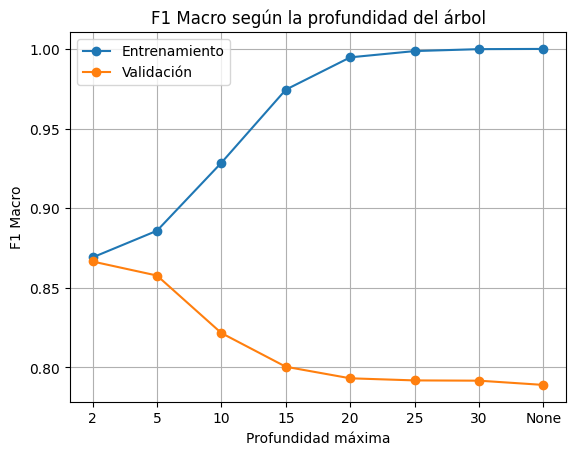

In [15]:
# Gráfica de F1 Macro

plt.plot(
    tabla["Profundidad"],
    tabla["F1 Entrenamiento"],
    marker="o",
    label="Entrenamiento"
)

plt.plot(
    tabla["Profundidad"],
    tabla["F1 Validación"],
    marker="o",
    label="Validación"
)

plt.xlabel("Profundidad máxima")
plt.ylabel("F1 Macro")
plt.title("F1 Macro según la profundidad del árbol")

plt.legend()
plt.grid()
plt.show()

**3.6 Identificar la mejor profundidad**

In [16]:
# Mejor profundidad

mejor_indice = np.argmax(f1_test)

print("Mejor profundidad:", profundidades[mejor_indice])
print("Mejor F1 Macro:", round(f1_test[mejor_indice], 3))

Mejor profundidad: 2
Mejor F1 Macro: 0.867


Al comparar las diferentes profundidades, se observa que el F1 Macro de entrenamiento aumenta conforme el árbol se vuelve más profundo, llegando prácticamente a 1. En validación el desempeño comienza a disminuir después de la profundidad 2, donde se obtuvo el mejor F1 Macro de aproximadamente 0.867.

Esto indica que los árboles más profundos presentan sobreajuste, ya que se ajustan demasiado a los datos de entrenamiento, pero tienen un menor desempeño al evaluar otras particiones. Una profundidad de 2 permite obtener una mejor generalización en este caso.

---
## 4. Optimización de hiperparámetros con RandomizedSearchCV

**4.1 Definir el espacio de búsqueda**

In [17]:
# Espacio de búsqueda de hiperparámetros

parametros = {
    "criterion": ["gini", "entropy"],
    "max_depth": list(range(5, 51)),
    "min_samples_split": list(range(2, 21))
}

**4.2 Configurar la validación cruzada**

In [18]:
# Validación cruzada estratificada

cv_random = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=3
)

**4.3 Configurar RandomizedSearchCV**

In [19]:
# Optimización con RandomizedSearchCV

arbol_random = DecisionTreeClassifier(random_state=7)

random_search = RandomizedSearchCV(
    estimator=arbol_random,
    param_distributions=parametros,
    n_iter=5,
    cv=cv_random,
    scoring="f1_macro",
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_modelo, y)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=10, random_state=3, shuffle=True),
                   estimator=DecisionTreeClassifier(random_state=7), n_iter=5,
                   n_jobs=-1,
                   param_distributions={'criterion': ['gini', 'entropy'],
                                        'max_depth': [5, 6, 7, 8, 9, 10, 11, 12,
                                                      13, 14, 15, 16, 17, 18,
                                                      19, 20, 21, 22, 23, 24,
                                                      25, 26, 27, 28, 29, 30,
                                                      31, 32, 33, 34, ...],
                                        'min_samples_split': [2, 3, 4, 5, 6, 7,
                                                              8, 9, 10, 11, 12,
                                                              13, 14, 15, 16,
                                                              17, 18, 19, 20]},
                   random_state=42, scoring='f1_macro')

**4.4 Mostrar los mejores resultados**

In [20]:
# Mejores resultados

print("Mejores hiperparámetros:")
print(random_search.best_params_)

print("\nMejor F1 Macro:", round(random_search.best_score_, 3))

Mejores hiperparámetros:
{'min_samples_split': 17, 'max_depth': 35, 'criterion': 'entropy'}

Mejor F1 Macro: 0.835


RandomizedSearchCV encontró como mejores hiperparámetros criterion="entropy", max_depth=35 y min_samples_split=17, obteniendo un F1 Macro promedio de aproximadamente 0.835. El modelo tuvo un buen desempeño al evaluar ambas clases mediante validación cruzada, el resultado es ligeramente menor al obtenido anteriormente con una profundidad de 2, puede deberse a que la búsqueda aleatoria solo evaluó cinco combinaciones y no incluyó profundidades menores a 5.

---
## 5. Optimización de hiperparámetros con GridSearchCV

**5.1 Definir el espacio de búsqueda**

In [21]:
# Espacio de búsqueda para GridSearchCV

parametros_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": list(range(5, 51)),
    "min_samples_split": list(range(2, 21))
}

print("Total de combinaciones:",
      2 * 46 * 19)

Total de combinaciones: 1748


**5.2 Configurar StratifiedKFold**

In [22]:
# Validación cruzada estratificada

cv_grid = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=3
)

**5.3 Configurar GridSearchCV**

In [23]:
# Optimización con GridSearchCV

arbol_grid = DecisionTreeClassifier(random_state=7)

grid_search = GridSearchCV(
    estimator=arbol_grid,
    param_grid=parametros_grid,
    cv=cv_grid,
    scoring="f1_macro",
    n_jobs=-1
)

grid_search.fit(X_modelo, y)

GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=3, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=7), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,
                                       16, 17, 18, 19, 20, 21, 22, 23, 24, 25,
                                       26, 27, 28, 29, 30, 31, 32, 33, 34, ...],
                         'min_samples_split': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11,
                                               12, 13, 14, 15, 16, 17, 18, 19,
                                               20]},
             scoring='f1_macro')

**5.4 Mostrar los mejores resultados**

In [24]:
# Mejores resultados de GridSearchCV

print("Mejores hiperparámetros:")
print(grid_search.best_params_)

print("\nMejor F1 Macro:", round(grid_search.best_score_, 3))

Mejores hiperparámetros:
{'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 13}

Mejor F1 Macro: 0.865


GridSearchCV encontró como mejores hiperparámetros criterion="entropy", max_depth=5 y min_samples_split=13, obteniendo un F1 Macro promedio de aproximadamente 0.865. Este resultado fue mayor que el obtenido con RandomizedSearchCV, que alcanzó 0.835. La búsqueda exhaustiva encontró una mejor combinación dentro del espacio evaluado, aunque tuvo que probar muchas más configuraciones.

---
## 6. Optimización de hiperparámetros con RandomizedSearchCV: Accuracy

**6.1 Definir el espacio de búsqueda**

In [25]:
# Espacio de búsqueda para Accuracy

parametros_accuracy = {
    "criterion": ["gini", "entropy"],
    "max_depth": list(range(5, 51)),
    "min_samples_split": list(range(2, 21))
}

**6.2 Configurar StratifiedKFold**

In [26]:
# Validación cruzada estratificada

cv_accuracy = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=3
)

**6.3 Configurar RandomizedSearchCV**

In [27]:
# Optimización con RandomizedSearchCV - Accuracy

arbol_random_accuracy = DecisionTreeClassifier(random_state=7)

random_accuracy = RandomizedSearchCV(
    estimator=arbol_random_accuracy,
    param_distributions=parametros_accuracy,
    n_iter=5,
    cv=cv_accuracy,
    scoring="accuracy",
    n_jobs=-1,
    random_state=42
)

random_accuracy.fit(X_modelo, y)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=10, random_state=3, shuffle=True),
                   estimator=DecisionTreeClassifier(random_state=7), n_iter=5,
                   n_jobs=-1,
                   param_distributions={'criterion': ['gini', 'entropy'],
                                        'max_depth': [5, 6, 7, 8, 9, 10, 11, 12,
                                                      13, 14, 15, 16, 17, 18,
                                                      19, 20, 21, 22, 23, 24,
                                                      25, 26, 27, 28, 29, 30,
                                                      31, 32, 33, 34, ...],
                                        'min_samples_split': [2, 3, 4, 5, 6, 7,
                                                              8, 9, 10, 11, 12,
                                                              13, 14, 15, 16,
                                                              17, 18, 19, 20]},
                   random_state=42, scoring='accuracy')

**6.4 Mostrar los mejores resultados**

In [28]:
# Mejores resultados de RandomizedSearchCV - Accuracy

print("Mejores hiperparámetros:")
print(random_accuracy.best_params_)

print("\nMejor Accuracy:", round(random_accuracy.best_score_, 3))

Mejores hiperparámetros:
{'min_samples_split': 17, 'max_depth': 35, 'criterion': 'entropy'}

Mejor Accuracy: 0.84


RandomizedSearchCV encontró como mejores hiperparámetros criterion="entropy", max_depth=35 y min_samples_split=17, obteniendo un Accuracy promedio de aproximadamente 0.840. Esta configuración es la misma que se obtuvo anteriormente utilizando F1 Macro, aunque las puntuaciones son ligeramente diferentes debido a que ambas métricas evalúan el desempeño del modelo de distinta manera.

---
## 7. Optimización de hiperparámetros con GridSearchCV: accuracy

**7.1 Definir el espacio de búsqueda**

In [29]:
# Espacio de búsqueda para GridSearchCV - Accuracy

parametros_grid_accuracy = {
    "criterion": ["gini", "entropy"],
    "max_depth": list(range(5, 51)),
    "min_samples_split": list(range(2, 21))
}

**7.2 Configurar StratifiedKFold**

In [30]:
# Validación cruzada estratificada

cv_grid_accuracy = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=3
)

**7.3 Configurar GridSearchCV**

In [31]:
# Optimización con GridSearchCV - Accuracy

arbol_grid_accuracy = DecisionTreeClassifier(random_state=7)

grid_accuracy = GridSearchCV(
    estimator=arbol_grid_accuracy,
    param_grid=parametros_grid_accuracy,
    cv=cv_grid_accuracy,
    scoring="accuracy",
    n_jobs=-1
)

grid_accuracy.fit(X_modelo, y)

GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=3, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=7), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,
                                       16, 17, 18, 19, 20, 21, 22, 23, 24, 25,
                                       26, 27, 28, 29, 30, 31, 32, 33, 34, ...],
                         'min_samples_split': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11,
                                               12, 13, 14, 15, 16, 17, 18, 19,
                                               20]},
             scoring='accuracy')

**7.4 Mostrar los mejores resultados**

In [32]:
# Mejores resultados de GridSearchCV - Accuracy

print("Mejores hiperparámetros:")
print(grid_accuracy.best_params_)

print("\nMejor Accuracy:", round(grid_accuracy.best_score_, 3))

Mejores hiperparámetros:
{'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 13}

Mejor Accuracy: 0.866


GridSearchCV encontró como mejores hiperparámetros criterion="entropy", max_depth=5 y min_samples_split=13, obteniendo un Accuracy promedio de aproximadamente 0.866. Este resultado fue mayor que el obtenido con RandomizedSearchCV, que alcanzó 0.840. La búsqueda exhaustiva encontró una mejor configuración entre las combinaciones evaluadas, aunque necesitó realizar más ajustes de modelos.

---
## 8.Actividad de reflexión y análisis

**¿Cuál método encontró mejores hiperparámetros?**

GridSearchCV encontró los mejores hiperparámetros, ya que obtuvo puntuaciones mayores en ambas métricas. Con F1 Macro alcanzó 0.865 y con Accuracy 0.866, mientras que RandomizedSearchCV obtuvo 0.835 y 0.840, respectivamente. La búsqueda exhaustiva encontró una mejor configuración dentro de los valores evaluados.

**¿Cuál fue más costoso computacionalmente?**

GridSearchCV fue más costoso porque evaluó las 1,748 combinaciones posibles de hiperparámetros utilizando 10 folds, lo que representa 17,480 ajustes durante la validación cruzada. En cambio, RandomizedSearchCV solamente evaluó 5 combinaciones, realizando 50 ajustes. GridSearchCV requiere más recursos y tiempo de ejecución.

**¿Los resultados en F1 Macro fueron distintos en ambos métodos de optimización? ¿Por qué?**

Sí. RandomizedSearchCV obtuvo un F1 Macro de 0.835, mientras que GridSearchCV alcanzó 0.865. Esta diferencia se debe a que RandomizedSearchCV solo probó cinco combinaciones aleatorias, GridSearchCV evaluó todas las combinaciones disponibles y pudo encontrar una configuración con mejor desempeño.

**¿Los resultados en Accuracy fueron distintos en ambos métodos de optimización? ¿Por qué?**

Sí. RandomizedSearchCV obtuvo un Accuracy de 0.840 y GridSearchCV alcanzó 0.866. GridSearchCV realizó una búsqueda más completa de los hiperparámetros, mientras que RandomizedSearchCV evaluó una cantidad limitada de combinaciones.

**¿Los valores de hiperparámetros fueron iguales en Accuracy y F1 Macro?**

Sí. En RandomizedSearchCV, ambas métricas seleccionaron criterion="entropy", max_depth=35 y min_samples_split=17. En GridSearchCV también coincidieron, seleccionando criterion="entropy", max_depth=5 y min_samples_split=13. En esta actividad, cambiar la métrica no modificó la configuración seleccionada dentro de cada método, aunque las puntuaciones obtenidas fueron ligeramente diferentes.